# Predicción de enfermedad cardiovascular con Machine Learning

Este notebook desarrolla una solución académica, completa y reproducible para un problema de clasificación binaria. El objetivo es predecir la variable `cardio`, donde `0` indica ausencia de enfermedad cardiovascular y `1` indica presencia de enfermedad cardiovascular.

La metodología compara cinco familias de modelos bajo la misma estrategia de validación, evita `data leakage` mediante `Pipeline`, analiza variables relevantes y estudia reducción de dimensión con PCA y UMAP.

## 1. Importación de librerías

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

try:
    import umap.umap_ as umap
except ImportError as exc:
    raise ImportError("Instala umap-learn con: pip install umap-learn") from exc

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", context="notebook")

In [ ]:
# Descargar el CSV
!gdown https://drive.google.com/uc?id=1m3qM4ubHRM-o08aVslcJwqX-msiO_yy0

Downloading...
From: https://drive.google.com/uc?id=1m3qM4ubHRM-o08aVslcJwqX-msiO_yy0
To: /content/cardio_train.csv
100% 2.94M/2.94M [00:00<00:00, 243MB/s]


## 2. Carga del dataset

Se asume que el archivo `cardio.csv` está en la misma carpeta del notebook. Si el archivo original está separado por punto y coma, cambie `pd.read_csv("cardio.csv")` por `pd.read_csv("cardio.csv", sep=";")`.

In [ ]:
# Definir el Path al CSV
csv_path = '/content/cardio_train.csv'

# Cargar el dataset especificando el separador por punto y coma
df = pd.read_csv(csv_path, sep=';')
display(df.head())

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [ ]:
# Definir los límites para el chequeo de sanidad
height_low, height_high = 100, 250
weight_low, weight_high = 40, 200
ap_hi_min, ap_hi_max = 50, 260
ap_lo_min, ap_lo_max = 0, 200

# Identificar filas con posibles medidas erróneas
outliers = df[
    (df['height'] < height_low) | (df['height'] > height_high) |
    (df['weight'] < weight_low) | (df['weight'] > weight_high) |
    (df['ap_hi'] < ap_hi_min) | (df['ap_hi'] > ap_hi_max) |
    (df['ap_lo'] < ap_lo_min) | (df['ap_hi'] > ap_lo_max) |
    (df['ap_hi'] < df['ap_lo'])
]

# Crear una versión limpia del dataframe
# Se excluyen los índices encontrados en el dataframe de outliers
df_clean = df.drop(outliers.index)

## 3. Limpieza y preprocesamiento

Se elimina `id` porque es un identificador sin significado predictivo. Se usa `age_years` como representación interpretable de la edad y se elimina `age` para evitar redundancia.

In [ ]:
df_clean = df.copy()

if "age_years" not in df_clean.columns:
    df_clean["age_years"] = (df_clean["age"] / 365.25).round(1)

df_clean = df_clean.drop(columns=[col for col in ["id", "age"] if col in df_clean.columns])

missing_table = df_clean.isna().sum().to_frame("missing_values")
missing_table["missing_pct"] = 100 * missing_table["missing_values"] / len(df_clean)
display(missing_table)

duplicated_count = df_clean.duplicated().sum()
print(f"Registros duplicados exactos: {duplicated_count}")

print("Columnas finales iniciales:", df_clean.columns.tolist())
print("Shape después de eliminar columnas irrelevantes:", df_clean.shape)

,missing_values,missing_pct
gender,0,0.0
height,0,0.0
weight,0,0.0
ap_hi,0,0.0
ap_lo,0,0.0
cholesterol,0,0.0
gluc,0,0.0
smoke,0,0.0
alco,0,0.0
active,0,0.0


Registros duplicados exactos: 674
Columnas finales iniciales: ['gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'age_years']
Shape después de eliminar columnas irrelevantes: (70000, 12)


### Detección de outliers

Se analizan `height`, `weight`, `ap_hi` y `ap_lo` mediante boxplots y percentiles. La limpieza elimina únicamente valores fisiológicamente absurdos, no observaciones extremas pero posibles. Esta decisión evita borrar variabilidad clínica real.

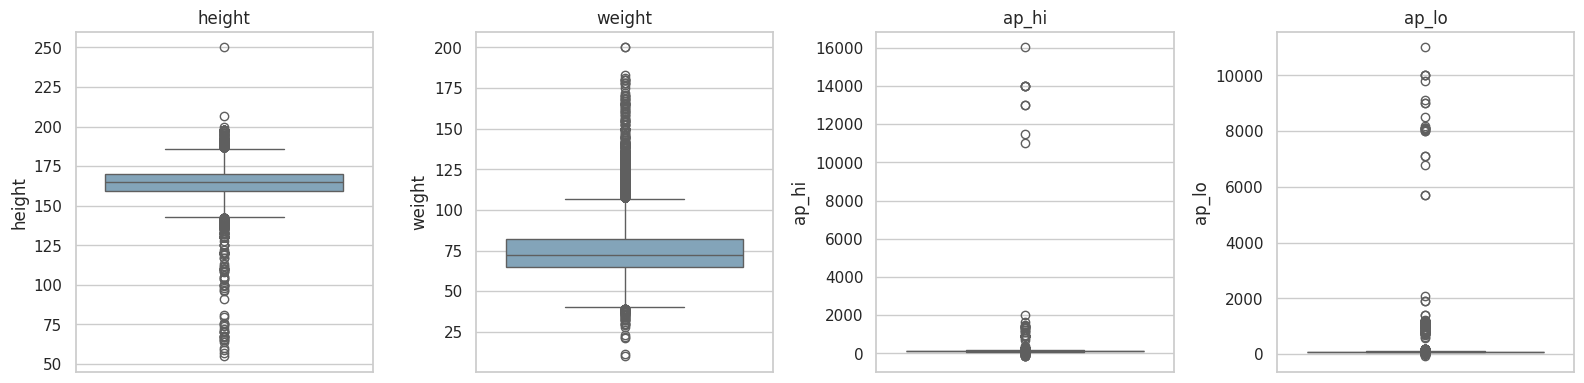

,0.000,0.001,0.010,0.050,0.500,0.950,0.990,0.999,1.000
height,55.0,120.0,147.0,152.0,165.0,178.0,184.0,190.0,250.0
weight,10.0,40.0,48.0,55.0,72.0,100.0,117.0,150.0,200.0
ap_hi,-150.0,12.0,90.0,100.0,120.0,160.0,180.0,220.0,16020.0
ap_lo,-70.0,40.0,60.0,70.0,80.0,100.0,1000.0,1110.0,11000.0


Registros antes de limpieza fisiológica: 70000
Registros después de limpieza fisiológica: 68612
Registros eliminados: 1388


,count,mean,std,min,25%,50%,75%,max
height,68612.0,164.413441,7.912792,120.0,159.0,165.0,170.0,207.0
weight,68612.0,74.114847,14.296078,30.0,65.0,72.0,82.0,200.0
ap_hi,68612.0,126.673250,16.683944,70.0,120.0,120.0,140.0,240.0
ap_lo,68612.0,81.304160,9.430397,40.0,80.0,80.0,90.0,160.0


In [ ]:
outlier_cols = ["height", "weight", "ap_hi", "ap_lo"]

fig, axes = plt.subplots(1, len(outlier_cols), figsize=(16, 4))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(y=df_clean[col], ax=ax, color="#7aa6c2")
    ax.set_title(col)
plt.tight_layout()
plt.show()

percentiles = df_clean[outlier_cols].quantile([0, 0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999, 1]).T
display(percentiles)

n_before = len(df_clean)
plausible_mask = (
    df_clean["height"].between(120, 220)
    & df_clean["weight"].between(30, 250)
    & df_clean["ap_hi"].between(70, 250)
    & df_clean["ap_lo"].between(40, 160)
    & (df_clean["ap_hi"] > df_clean["ap_lo"])
)
df_clean = df_clean.loc[plausible_mask].reset_index(drop=True)

print(f"Registros antes de limpieza fisiológica: {n_before}")
print(f"Registros después de limpieza fisiológica: {len(df_clean)}")
print(f"Registros eliminados: {n_before - len(df_clean)}")

display(df_clean[outlier_cols].describe().T)

**Interpretación.** Las reglas anteriores conservan valores clínicamente posibles y eliminan alturas, pesos o presiones incompatibles con un registro fisiológico razonable. Además, exigir `ap_hi > ap_lo` corrige casos donde la presión sistólica no supera a la diastólica, una inconsistencia clara para este problema.

## 4. Análisis exploratorio de datos

,proportion,percentage
cardio,,
0,0.505305,50.530519
1,0.494695,49.469481


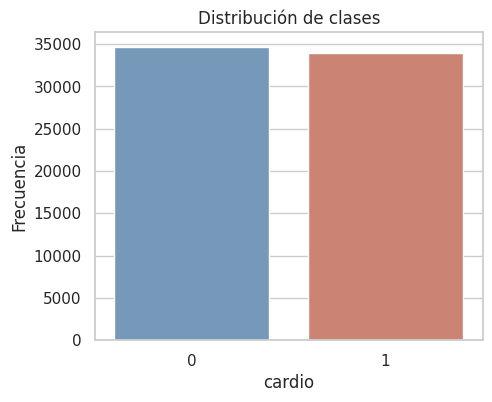

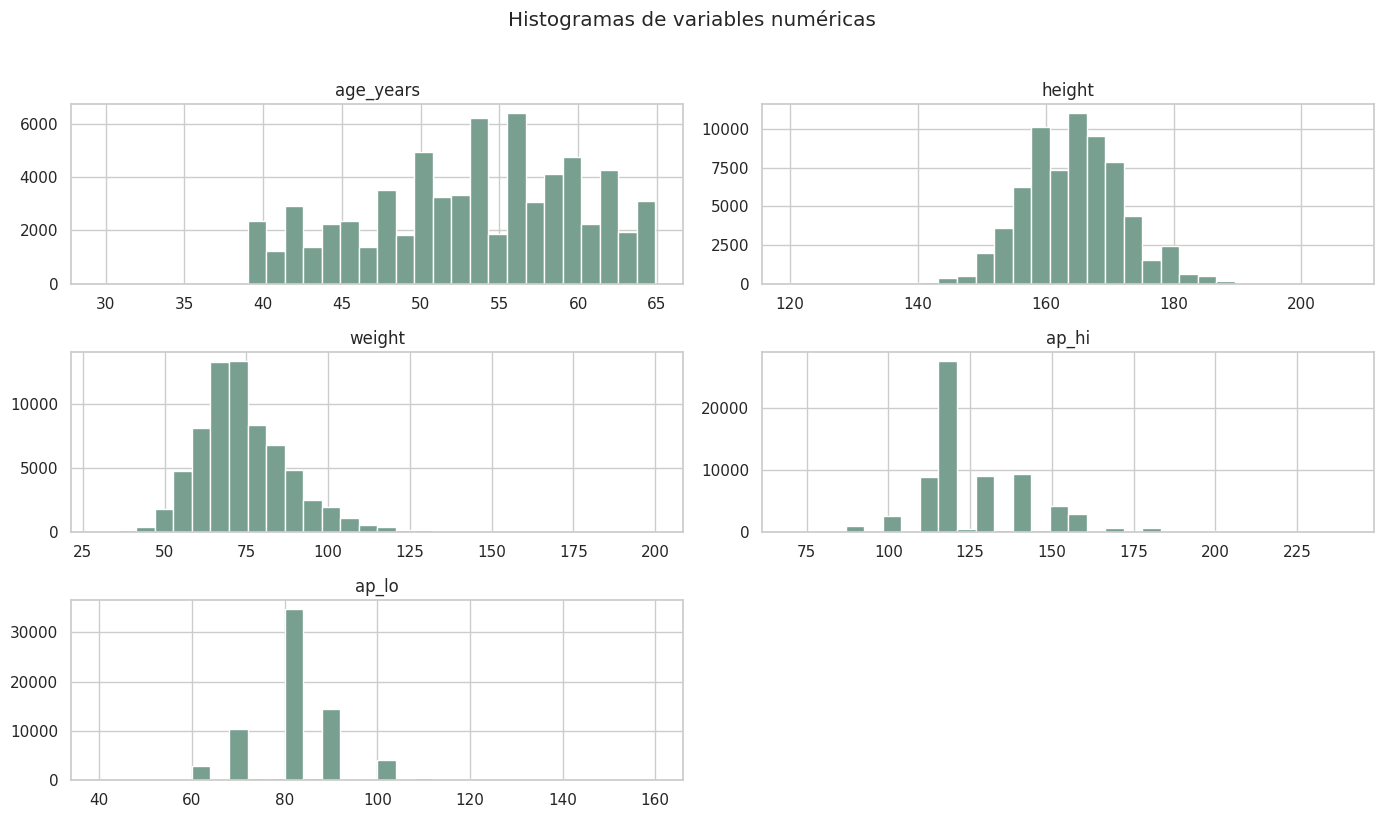

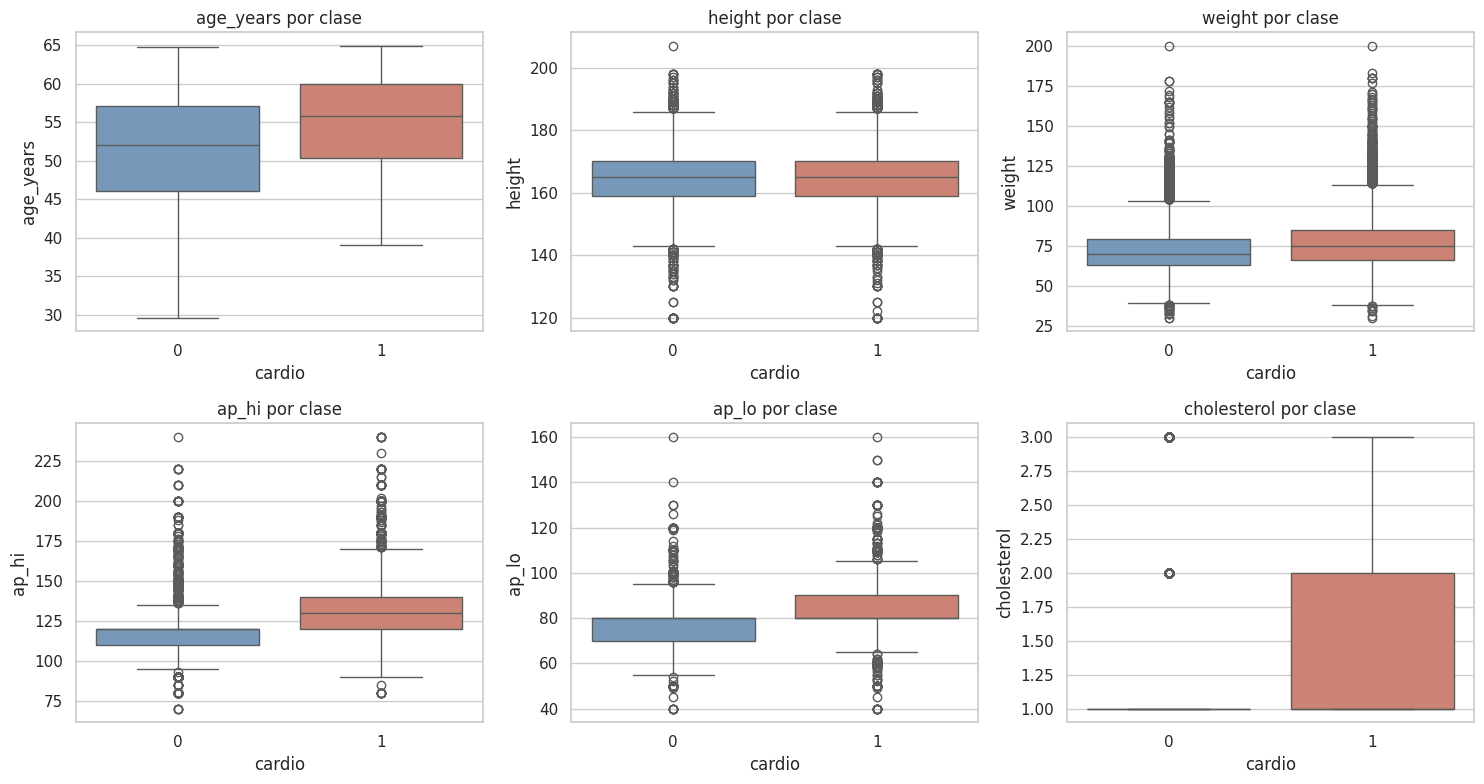

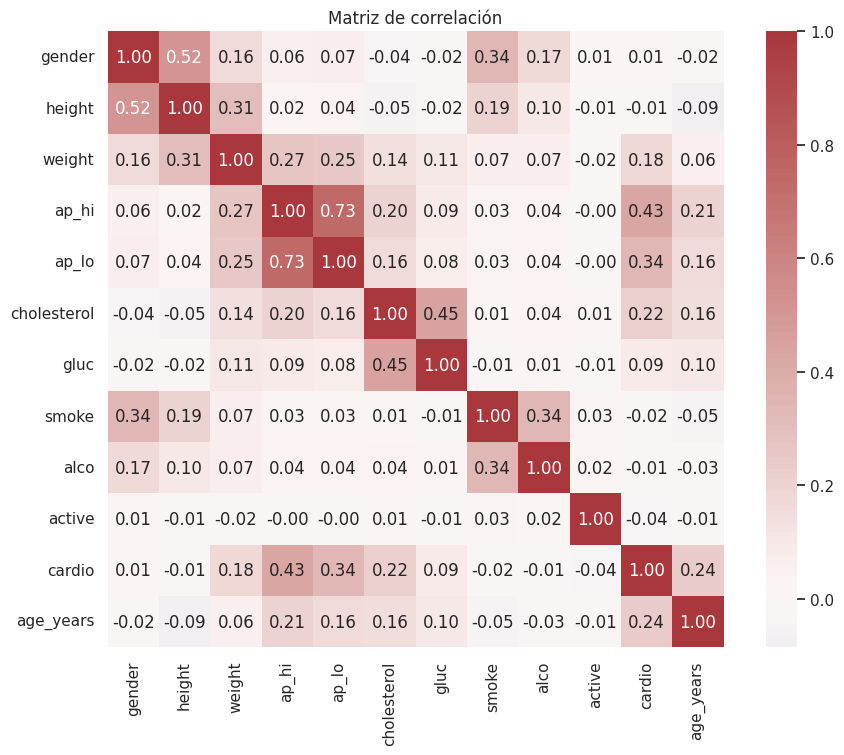

,correlación con cardio
ap_hi,0.428074
ap_lo,0.340512
age_years,0.239389
cholesterol,0.221431
weight,0.180122
gluc,0.089706
gender,0.007182
alco,-0.008571
height,-0.011826
smoke,-0.016361


In [ ]:
class_dist = df_clean["cardio"].value_counts(normalize=True).rename("proportion").to_frame()
class_dist["percentage"] = 100 * class_dist["proportion"]
display(class_dist)

plt.figure(figsize=(5, 4))
sns.countplot(data=df_clean, x="cardio", palette=["#6b9ac4", "#d97b66"])
plt.title("Distribución de clases")
plt.xlabel("cardio")
plt.ylabel("Frecuencia")
plt.show()

numeric_cols = ["age_years", "height", "weight", "ap_hi", "ap_lo"]
df_clean[numeric_cols].hist(figsize=(14, 8), bins=30, color="#789f90", edgecolor="white")
plt.suptitle("Histogramas de variables numéricas", y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), numeric_cols + ["cholesterol"]):
    sns.boxplot(data=df_clean, x="cardio", y=col, ax=ax, palette=["#6b9ac4", "#d97b66"])
    ax.set_title(f"{col} por clase")
plt.tight_layout()
plt.show()

corr = df_clean.corr(numeric_only=True)
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Matriz de correlación")
plt.show()

target_corr = corr["cardio"].drop("cardio").sort_values(ascending=False)
display(target_corr.to_frame("correlación con cardio"))

**Interpretación del EDA.** Se espera una distribución de clases cercana al equilibrio, por lo que no se aplican técnicas de balanceo. Las correlaciones reportadas previamente sugieren que `ap_hi` y `ap_lo` son las variables lineales más asociadas con `cardio`, seguidas de edad, colesterol y peso. La relación fuerte entre `ap_hi` y `ap_lo` es esperable porque ambas miden presión arterial. La correlación entre `cholesterol` y `gluc` indica que algunos factores metabólicos tienden a elevarse conjuntamente, aunque no son equivalentes.

## 5. Definición del problema de ML

Se separan entrenamiento, validación y prueba con proporciones 70%, 15% y 15%, manteniendo estratificación por la variable objetivo.

In [ ]:
X = df_clean.drop(columns="cardio")
y = df_clean["cardio"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, y_train.mean().round(4))
print("Validation:", X_val.shape, y_val.mean().round(4))
print("Test:", X_test.shape, y_test.mean().round(4))

Train: (48028, 11) 0.4947
Validation: (10292, 11) 0.4948
Test: (10292, 11) 0.4947


## 6. Escalamiento y pipelines

Los modelos sensibles a escala usan `StandardScaler`: Regresión Logística, KNN, MLP y SVM. Random Forest no requiere escalamiento. El escalamiento se ajusta solo con datos de entrenamiento dentro del `Pipeline`, evitando `data leakage`.

In [ ]:
scaled_pipeline = lambda estimator: Pipeline([
    ("scaler", StandardScaler()),
    ("model", estimator),
])

unscaled_pipeline = lambda estimator: Pipeline([
    ("model", estimator),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 7. Métricas de evaluación

- Accuracy: proporción total de predicciones correctas.
- Precision: de los casos predichos como positivos, proporción realmente positiva.
- Recall: de los positivos reales, proporción detectada por el modelo.
- F1 Score: media armónica entre precision y recall.
- ROC AUC: probabilidad de que el modelo asigne mayor puntaje a un positivo que a un negativo.

ROC-AUC se usa como métrica principal porque el dataset está casi balanceado y porque evalúa la capacidad discriminativa del modelo a través de todos los umbrales, no solo con el punto de corte 0.5.

In [ ]:
def get_scores(estimator, X_data):
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X_data)[:, 1]
    return estimator.decision_function(X_data)

def evaluate_model(estimator, X_data, y_data, dataset_name):
    y_pred = estimator.predict(X_data)
    y_score = get_scores(estimator, X_data)
    return {
        "dataset": dataset_name,
        "Accuracy": accuracy_score(y_data, y_pred),
        "Precision": precision_score(y_data, y_pred),
        "Recall": recall_score(y_data, y_pred),
        "F1": f1_score(y_data, y_pred),
        "ROC AUC": roc_auc_score(y_data, y_score),
    }

def show_confusion_and_roc(estimator, X_data, y_data, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    ConfusionMatrixDisplay.from_estimator(estimator, X_data, y_data, ax=axes[0], cmap="Blues")
    axes[0].set_title(f"Matriz de confusión: {title}")
    RocCurveDisplay.from_estimator(estimator, X_data, y_data, ax=axes[1])
    axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
    axes[1].set_title(f"Curva ROC: {title}")
    plt.tight_layout()
    plt.show()

def grid_table(param_grid):
    return pd.DataFrame({k: [v] for k, v in param_grid.items()}).T.rename(columns={0: "valores evaluados"})

def run_grid_search(model_name, pipeline, param_grid):
    print(f"Modelo: {model_name}")
    print("Hiperparámetros evaluados:")
    display(grid_table(param_grid))
    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        return_train_score=True,
        refit=True,
    )
    grid.fit(X_train, y_train)
    print("Mejores hiperparámetros:", grid.best_params_)
    print("Mejor ROC-AUC CV:", round(grid.best_score_, 4))
    cv_results = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")
    display(cv_results[["rank_test_score", "mean_train_score", "mean_test_score", "std_test_score", "params"]].head(10))
    metrics = pd.DataFrame([
        evaluate_model(grid.best_estimator_, X_train, y_train, "train"),
        evaluate_model(grid.best_estimator_, X_val, y_val, "validation"),
        evaluate_model(grid.best_estimator_, X_test, y_test, "test"),
    ])
    metrics.insert(0, "Modelo", model_name)
    display(metrics)
    show_confusion_and_roc(grid.best_estimator_, X_val, y_val, f"{model_name} - validación")
    return grid, metrics, cv_results

all_metrics = []
best_estimators = {}
cv_results_dict = {}

## 8. Validación y ajuste de hiperparámetros

Todos los modelos usan `StratifiedKFold(n_splits=5)` y `GridSearchCV` con `scoring="roc_auc"`. La misma partición de entrenamiento, validación y prueba se mantiene para todos.

## 9. Modelo 1: Regresión Logística

Modelo: Regresión Logística
Hiperparámetros evaluados:


,valores evaluados
model__C,"[0.01, 0.1, 1, 10]"
model__penalty,"[l1, l2]"


Mejores hiperparámetros: {'model__C': 0.1, 'model__penalty': 'l1'}
Mejor ROC-AUC CV: 0.7914


,rank_test_score,mean_train_score,mean_test_score,std_test_score,params
2,1,0.791551,0.791360,0.004659,"{'model__C': 0.1, 'model__penalty': 'l1'}"
4,2,0.791543,0.791354,0.004651,"{'model__C': 1, 'model__penalty': 'l1'}"
6,3,0.791542,0.791352,0.004651,"{'model__C': 10, 'model__penalty': 'l1'}"
7,4,0.791542,0.791352,0.004651,"{'model__C': 10, 'model__penalty': 'l2'}"
5,5,0.791542,0.791352,0.004652,"{'model__C': 1, 'model__penalty': 'l2'}"
3,6,0.791537,0.791349,0.004654,"{'model__C': 0.1, 'model__penalty': 'l2'}"
0,7,0.791508,0.791321,0.004744,"{'model__C': 0.01, 'model__penalty': 'l1'}"
1,8,0.791480,0.791289,0.004688,"{'model__C': 0.01, 'model__penalty': 'l2'}"


,Modelo,dataset,Accuracy,Precision,Recall,F1,ROC AUC
0,Regresión Logística,train,0.727617,0.754033,0.666947,0.707822,0.791527
1,Regresión Logística,validation,0.724738,0.750944,0.663786,0.704680,0.790673
2,Regresión Logística,test,0.727847,0.753095,0.669220,0.708684,0.790954


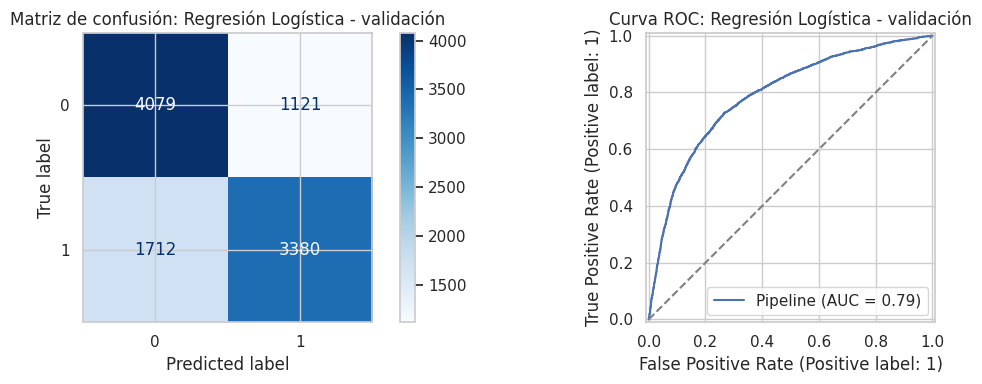

In [ ]:
logreg_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__penalty": ["l1", "l2"],
}
logreg_pipe = scaled_pipeline(LogisticRegression(solver="liblinear", max_iter=1000, random_state=RANDOM_STATE))

logreg_search, logreg_metrics, logreg_cv = run_grid_search("Regresión Logística", logreg_pipe, logreg_grid)
all_metrics.append(logreg_metrics)
best_estimators["Regresión Logística"] = logreg_search.best_estimator_
cv_results_dict["Regresión Logística"] = logreg_cv

## 10. Modelo 2: KNN

Modelo: KNN
Hiperparámetros evaluados:


,valores evaluados
model__n_neighbors,"[15, 31, 51]"
model__weights,"[uniform, distance]"
model__metric,"[euclidean, manhattan]"


Mejores hiperparámetros: {'model__metric': 'manhattan', 'model__n_neighbors': 51, 'model__weights': 'uniform'}
Mejor ROC-AUC CV: 0.7895


,rank_test_score,mean_train_score,mean_test_score,std_test_score,params
10,1,0.806302,0.789478,0.003422,"{'model__metric': 'manhattan', 'model__n_neigh..."
4,2,0.805618,0.788924,0.002792,"{'model__metric': 'euclidean', 'model__n_neigh..."
8,3,0.812519,0.786167,0.002747,"{'model__metric': 'manhattan', 'model__n_neigh..."
2,4,0.811452,0.785292,0.002648,"{'model__metric': 'euclidean', 'model__n_neigh..."
5,5,0.999977,0.782261,0.003326,"{'model__metric': 'euclidean', 'model__n_neigh..."
11,6,0.999977,0.781856,0.003907,"{'model__metric': 'manhattan', 'model__n_neigh..."
3,7,0.999977,0.777993,0.003540,"{'model__metric': 'euclidean', 'model__n_neigh..."
9,8,0.999977,0.777566,0.003680,"{'model__metric': 'manhattan', 'model__n_neigh..."
6,9,0.827266,0.777153,0.004299,"{'model__metric': 'manhattan', 'model__n_neigh..."
0,10,0.827176,0.776735,0.003541,"{'model__metric': 'euclidean', 'model__n_neigh..."


,Modelo,dataset,Accuracy,Precision,Recall,F1,ROC AUC
0,KNN,train,0.737486,0.761625,0.683152,0.720257,0.807222
1,KNN,validation,0.726487,0.750165,0.670463,0.708078,0.794661
2,KNN,test,0.731733,0.756382,0.675113,0.713441,0.792867


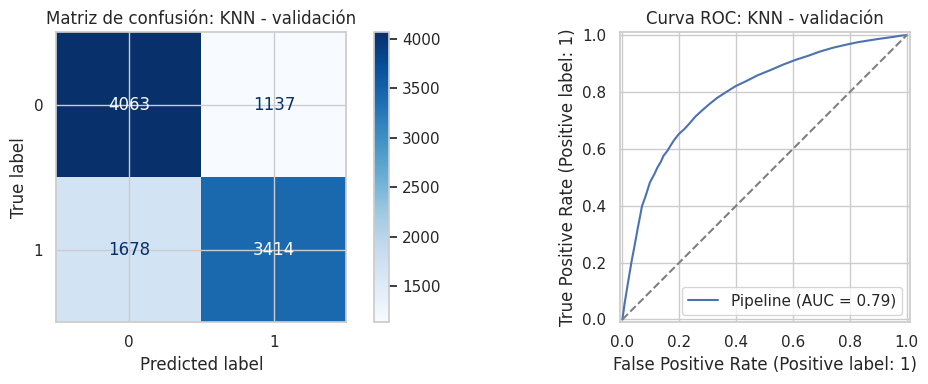

In [ ]:
knn_grid = {
    "model__n_neighbors": [15, 31, 51],
    "model__weights": ["uniform", "distance"],
    "model__metric": ["euclidean", "manhattan"],
}
knn_pipe = scaled_pipeline(KNeighborsClassifier())

knn_search, knn_metrics, knn_cv = run_grid_search("KNN", knn_pipe, knn_grid)
all_metrics.append(knn_metrics)
best_estimators["KNN"] = knn_search.best_estimator_
cv_results_dict["KNN"] = knn_cv

## 11. Modelo 3: Random Forest

Modelo: Random Forest
Hiperparámetros evaluados:


,valores evaluados
model__n_estimators,"[150, 300]"
model__max_depth,"[8, None]"
model__min_samples_split,"[2, 10]"
model__min_samples_leaf,[1]


Mejores hiperparámetros: {'model__max_depth': 8, 'model__min_samples_leaf': 1, 'model__min_samples_split': 10, 'model__n_estimators': 300}
Mejor ROC-AUC CV: 0.7995


,rank_test_score,mean_train_score,mean_test_score,std_test_score,params
3,1,0.814661,0.799474,0.004219,"{'model__max_depth': 8, 'model__min_samples_le..."
1,2,0.815621,0.799458,0.004248,"{'model__max_depth': 8, 'model__min_samples_le..."
0,3,0.815478,0.799355,0.004315,"{'model__max_depth': 8, 'model__min_samples_le..."
2,4,0.814621,0.799276,0.004245,"{'model__max_depth': 8, 'model__min_samples_le..."
7,5,0.962189,0.788233,0.004012,"{'model__max_depth': None, 'model__min_samples..."
6,6,0.961670,0.787476,0.003662,"{'model__max_depth': None, 'model__min_samples..."
5,7,0.999956,0.772619,0.003637,"{'model__max_depth': None, 'model__min_samples..."
4,8,0.999950,0.772043,0.003479,"{'model__max_depth': None, 'model__min_samples..."


,Modelo,dataset,Accuracy,Precision,Recall,F1,ROC AUC
0,Random Forest,train,0.740339,0.769661,0.678017,0.720938,0.812385
1,Random Forest,validation,0.734745,0.761052,0.676159,0.716098,0.800713
2,Random Forest,test,0.732414,0.758232,0.673934,0.713602,0.798517


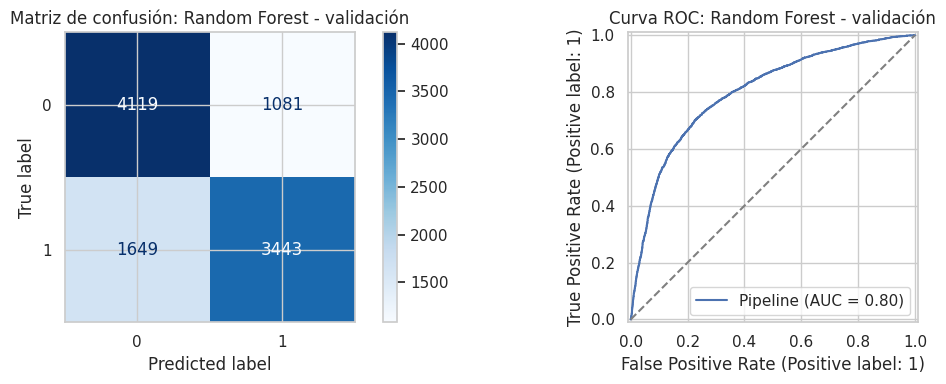

,Variable,Importancia
3,ap_hi,0.490861
4,ap_lo,0.211164
10,age_years,0.133165
5,cholesterol,0.083582
2,weight,0.043355
1,height,0.014101
6,gluc,0.010098
9,active,0.006085
7,smoke,0.003002
0,gender,0.002383


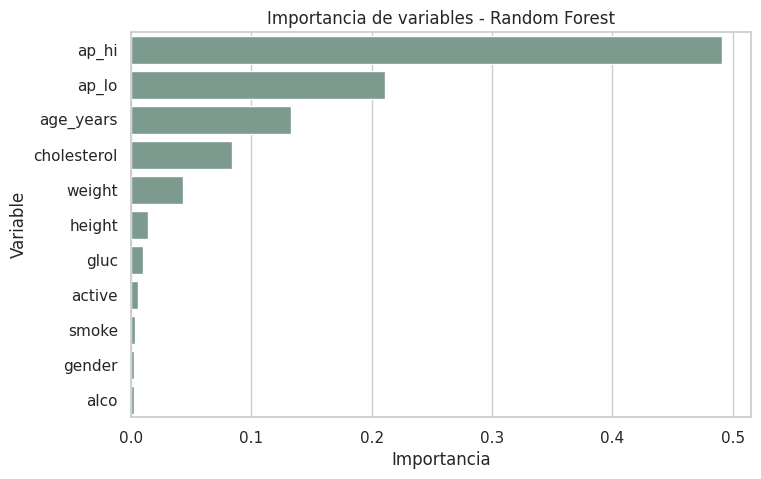

In [ ]:
rf_grid = {
    "model__n_estimators": [150, 300],
    "model__max_depth": [8, None],
    "model__min_samples_split": [2, 10],
    "model__min_samples_leaf": [1],
}
rf_pipe = unscaled_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))

rf_search, rf_metrics, rf_cv = run_grid_search("Random Forest", rf_pipe, rf_grid)
all_metrics.append(rf_metrics)
best_estimators["Random Forest"] = rf_search.best_estimator_
cv_results_dict["Random Forest"] = rf_cv

rf_model = rf_search.best_estimator_.named_steps["model"]
rf_importance = pd.DataFrame({"Variable": X_train.columns, "Importancia": rf_model.feature_importances_})
rf_importance = rf_importance.sort_values("Importancia", ascending=False)
display(rf_importance)

plt.figure(figsize=(8, 5))
sns.barplot(data=rf_importance, x="Importancia", y="Variable", color="#789f90")
plt.title("Importancia de variables - Random Forest")
plt.show()

## 12. Modelo 4: MLPClassifier

Modelo: MLP
Hiperparámetros evaluados:


,valores evaluados
model__hidden_layer_sizes,"[(32,), (64,)]"
model__alpha,"[0.0001, 0.001]"
model__learning_rate_init,[0.001]


Mejores hiperparámetros: {'model__alpha': 0.001, 'model__hidden_layer_sizes': (64,), 'model__learning_rate_init': 0.001}
Mejor ROC-AUC CV: 0.7978


,rank_test_score,mean_train_score,mean_test_score,std_test_score,params
3,1,0.800899,0.797773,0.003699,"{'model__alpha': 0.001, 'model__hidden_layer_s..."
1,2,0.800627,0.797671,0.003713,"{'model__alpha': 0.0001, 'model__hidden_layer_..."
2,3,0.799927,0.797661,0.003321,"{'model__alpha': 0.001, 'model__hidden_layer_s..."
0,4,0.799723,0.797476,0.003375,"{'model__alpha': 0.0001, 'model__hidden_layer_..."


,Modelo,dataset,Accuracy,Precision,Recall,F1,ROC AUC
0,MLP,train,0.737445,0.750438,0.703060,0.725977,0.803475
1,MLP,validation,0.734745,0.746761,0.701885,0.723628,0.799808
2,MLP,test,0.736203,0.747810,0.704184,0.725341,0.801443


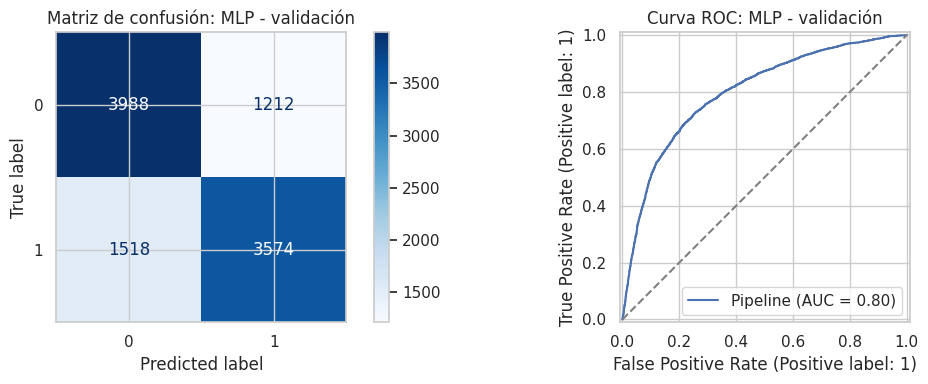

In [ ]:
mlp_grid = {
    "model__hidden_layer_sizes": [(32,), (64,)],
    "model__alpha": [0.0001, 0.001],
    "model__learning_rate_init": [0.001],
}
mlp_pipe = scaled_pipeline(
    MLPClassifier(
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.15,
        random_state=RANDOM_STATE,
    )
)

mlp_search, mlp_metrics, mlp_cv = run_grid_search("MLP", mlp_pipe, mlp_grid)
all_metrics.append(mlp_metrics)
best_estimators["MLP"] = mlp_search.best_estimator_
cv_results_dict["MLP"] = mlp_cv

## 13. Modelo 5: SVM

SVM puede ser costoso en datasets medianos. Se usa una malla reducida pero suficiente para comparar kernels lineal y RBF.

Modelo: SVM
Hiperparámetros evaluados:


,valores evaluados
model__C,"[0.5, 1]"
model__kernel,"[linear, rbf]"
model__gamma,[scale]


Mejores hiperparámetros: {'model__C': 0.5, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Mejor ROC-AUC CV: 0.7091


,rank_test_score,mean_train_score,mean_test_score,std_test_score,params
0,1,0.711079,0.709099,0.060535,"{'model__C': 0.5, 'model__gamma': 'scale', 'mo..."
2,2,0.575589,0.571341,0.101071,"{'model__C': 1, 'model__gamma': 'scale', 'mode..."
1,3,0.550360,0.548851,0.032045,"{'model__C': 0.5, 'model__gamma': 'scale', 'mo..."
3,4,0.520043,0.517231,0.056356,"{'model__C': 1, 'model__gamma': 'scale', 'mode..."


,Modelo,dataset,Accuracy,Precision,Recall,F1,ROC AUC
0,SVM,train,0.494940,0.494809,0.998906,0.661796,0.668248
1,SVM,validation,0.495239,0.494989,0.999018,0.661982,0.658582
2,SVM,test,0.494462,0.494551,0.998429,0.661461,0.660794


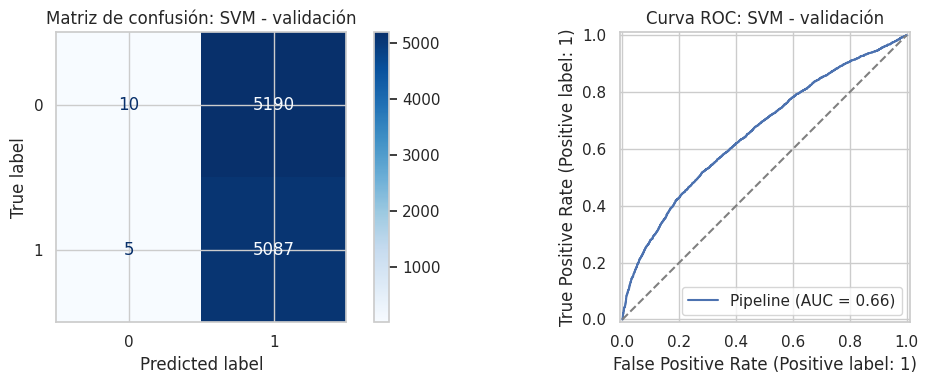

In [ ]:
svm_grid = {
    "model__C": [0.5, 1],
    "model__kernel": ["linear", "rbf"],
    "model__gamma": ["scale"],
}
svm_pipe = scaled_pipeline(SVC(probability=False, random_state=RANDOM_STATE, cache_size=1000, max_iter=3000))

svm_search, svm_metrics, svm_cv = run_grid_search("SVM", svm_pipe, svm_grid)
all_metrics.append(svm_metrics)
best_estimators["SVM"] = svm_search.best_estimator_
cv_results_dict["SVM"] = svm_cv

## 14. Comparación global de modelos

In [ ]:
metrics_all = pd.concat(all_metrics, ignore_index=True)
validation_summary = (
    metrics_all[metrics_all["dataset"] == "validation"]
    .drop(columns="dataset")
    .sort_values("ROC AUC", ascending=False)
    .reset_index(drop=True)
)
display(validation_summary)

best_model_name = validation_summary.loc[0, "Modelo"]
second_model_name = validation_summary.loc[1, "Modelo"]
top2_model_names = [best_model_name, second_model_name]

print(f"Mejor modelo según ROC-AUC de validación: {best_model_name}")
print(f"Segundo mejor modelo según ROC-AUC de validación: {second_model_name}")

,Modelo,Accuracy,Precision,Recall,F1,ROC AUC
0,Random Forest,0.734745,0.761052,0.676159,0.716098,0.800713
1,MLP,0.734745,0.746761,0.701885,0.723628,0.799808
2,KNN,0.726487,0.750165,0.670463,0.708078,0.794661
3,Regresión Logística,0.724738,0.750944,0.663786,0.704680,0.790673
4,SVM,0.495239,0.494989,0.999018,0.661982,0.658582


Mejor modelo según ROC-AUC de validación: Random Forest
Segundo mejor modelo según ROC-AUC de validación: MLP


## 15. Análisis individual de variables

Se combinan tres criterios: correlación con la variable objetivo, información mutua e importancia de Random Forest.

,abs_corr_cardio,mutual_information,rf_importance,rank_abs_corr_cardio,rank_mutual_information,rank_rf_importance,rank_promedio
ap_hi,0.429116,0.121765,0.490861,1.0,1.0,1.0,1.000000
ap_lo,0.342610,0.075667,0.211164,2.0,2.0,2.0,2.000000
age_years,0.240623,0.034157,0.133165,3.0,3.0,3.0,3.000000
cholesterol,0.216631,0.028193,0.083582,4.0,4.0,4.0,4.000000
weight,0.179890,0.019883,0.043355,5.0,5.0,5.0,5.000000
gluc,0.085158,0.007092,0.010098,6.0,6.0,7.0,6.333333
active,0.038740,0.004686,0.006085,7.0,7.0,8.0,7.333333
height,0.009376,0.001699,0.014101,9.0,9.0,6.0,8.000000
smoke,0.014935,0.000000,0.003002,8.0,10.5,9.0,9.166667
gender,0.007005,0.004586,0.002383,10.0,8.0,10.0,9.333333


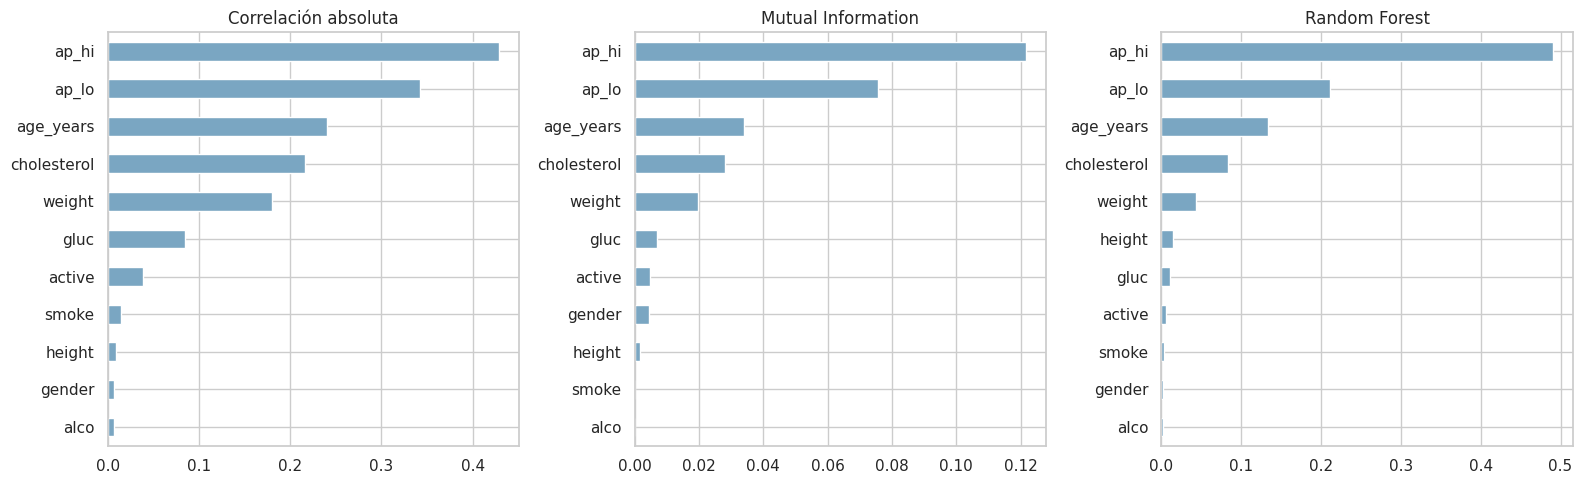

In [ ]:
corr_rank = X_train.join(y_train).corr(numeric_only=True)["cardio"].drop("cardio").abs()
mi_values = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)
mi_rank = pd.Series(mi_values, index=X_train.columns)

variable_ranking = pd.DataFrame({
    "abs_corr_cardio": corr_rank,
    "mutual_information": mi_rank,
    "rf_importance": rf_importance.set_index("Variable")["Importancia"],
})
for col in variable_ranking.columns:
    variable_ranking[f"rank_{col}"] = variable_ranking[col].rank(ascending=False)
variable_ranking["rank_promedio"] = variable_ranking[[c for c in variable_ranking.columns if c.startswith("rank_")]].mean(axis=1)
variable_ranking = variable_ranking.sort_values("rank_promedio")
display(variable_ranking)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col, title in zip(
    axes,
    ["abs_corr_cardio", "mutual_information", "rf_importance"],
    ["Correlación absoluta", "Mutual Information", "Random Forest"],
):
    variable_ranking.sort_values(col).plot(kind="barh", y=col, ax=ax, legend=False, color="#7aa6c2")
    ax.set_title(title)
plt.tight_layout()
plt.show()

**Discusión de variables.** Si los resultados reproducen el EDA esperado, `ap_hi`, `ap_lo`, `age_years`, `cholesterol` y `weight` deberían dominar el ranking. Variables de comportamiento como `smoke`, `alco` o `active` pueden aportar menos señal individual, pero no se eliminan automáticamente porque algunos modelos pueden capturar interacciones débiles.

## 16. Reducción de dimensión con PCA

PCA se aplica únicamente sobre datos escalados. El número de componentes se selecciona con 95% de varianza explicada acumulada.

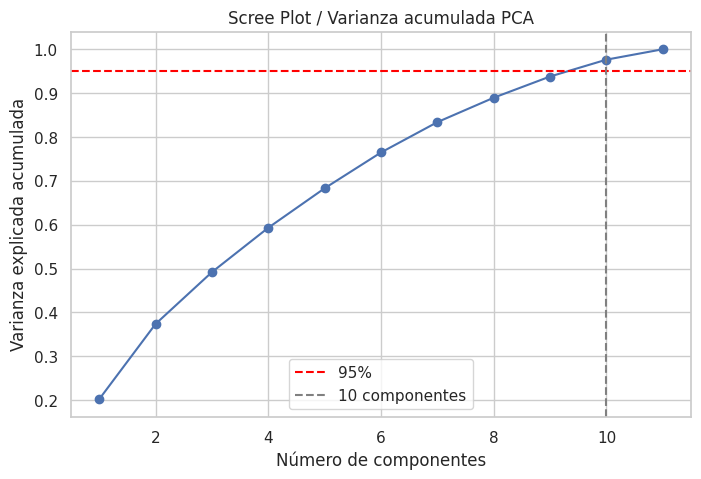

Componentes seleccionados: 10
Variables originales: 11
Reducción obtenida: 9.09%


In [ ]:
scaler_for_pca = StandardScaler()
X_train_scaled = scaler_for_pca.fit_transform(X_train)
X_val_scaled = scaler_for_pca.transform(X_val)
X_test_scaled = scaler_for_pca.transform(X_test)

pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components_95 = int(np.argmax(cum_var >= 0.95) + 1)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker="o")
plt.axhline(0.95, color="red", linestyle="--", label="95%")
plt.axvline(n_components_95, color="gray", linestyle="--", label=f"{n_components_95} componentes")
plt.xlabel("Número de componentes")
plt.ylabel("Varianza explicada acumulada")
plt.title("Scree Plot / Varianza acumulada PCA")
plt.legend()
plt.show()

reduction_pct_pca = 100 * (1 - n_components_95 / X_train.shape[1])
print(f"Componentes seleccionados: {n_components_95}")
print(f"Variables originales: {X_train.shape[1]}")
print(f"Reducción obtenida: {reduction_pct_pca:.2f}%")

## 17. Reentrenamiento con PCA

In [ ]:
def pca_pipeline_from_best(best_estimator, n_components):
    model = clone(best_estimator.named_steps["model"])
    return Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n_components, random_state=RANDOM_STATE)),
        ("model", model),
    ])

pca_rows = []
pca_estimators = {}
for name in top2_model_names:
    pipe = pca_pipeline_from_best(best_estimators[name], n_components_95)
    pipe.fit(X_train, y_train)
    pca_estimators[name] = pipe
    row = evaluate_model(pipe, X_val, y_val, "validation")
    row["Modelo"] = name
    row["Representación"] = "PCA"
    pca_rows.append(row)

original_top2 = validation_summary[validation_summary["Modelo"].isin(top2_model_names)].copy()
original_top2["Representación"] = "Original"
pca_summary = pd.concat([original_top2, pd.DataFrame(pca_rows)], ignore_index=True, sort=False)
display(pca_summary[["Representación", "Modelo", "Accuracy", "Precision", "Recall", "F1", "ROC AUC"]].sort_values("ROC AUC", ascending=False))

,Representación,Modelo,Accuracy,Precision,Recall,F1,ROC AUC
0,Original,Random Forest,0.734745,0.761052,0.676159,0.716098,0.800713
1,Original,MLP,0.734745,0.746761,0.701885,0.723628,0.799808
3,PCA,MLP,0.729984,0.748549,0.684014,0.714828,0.794147
2,PCA,Random Forest,0.730470,0.750866,0.681265,0.714374,0.791775


**Discusión PCA.** PCA puede reducir complejidad al combinar variables correlacionadas, como `ap_hi` y `ap_lo`. Sin embargo, al ser una transformación no supervisada, no garantiza mejorar ROC-AUC; su valor académico principal está en estudiar el compromiso entre desempeño y dimensionalidad.

## 18. Reducción de dimensión con UMAP

UMAP se evalúa con `n_components = 2, 3, 5`. Para reducir tiempo, el embedding se ajusta sobre entrenamiento y luego transforma validación y prueba.

UMAP con 2 componentes: reducción 81.82%
UMAP con 3 componentes: reducción 72.73%
UMAP con 5 componentes: reducción 54.55%


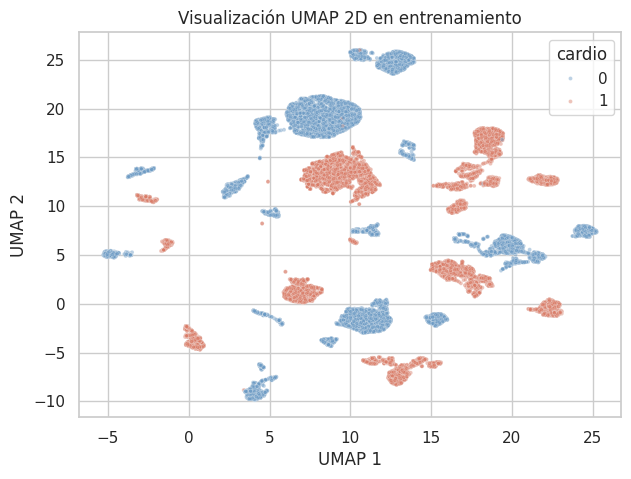

Configuración final seleccionada: 5 componentes, por conservar más información que 2D/3D sin volver a la dimensionalidad original.


In [ ]:
umap_embeddings = {}
for n_comp in [2, 3, 5]:
    reducer = umap.UMAP(
        n_components=n_comp,
        n_neighbors=30,
        min_dist=0.1,
        metric="euclidean",
        random_state=RANDOM_STATE,
    )
    X_train_umap = reducer.fit_transform(X_train_scaled, y_train)
    X_val_umap = reducer.transform(X_val_scaled)
    X_test_umap = reducer.transform(X_test_scaled)
    umap_embeddings[n_comp] = (reducer, X_train_umap, X_val_umap, X_test_umap)
    print(f"UMAP con {n_comp} componentes: reducción {100 * (1 - n_comp / X_train.shape[1]):.2f}%")

embed_2d = umap_embeddings[2][1]
plt.figure(figsize=(7, 5))
sns.scatterplot(x=embed_2d[:, 0], y=embed_2d[:, 1], hue=y_train, s=8, alpha=0.45, palette=["#6b9ac4", "#d97b66"])
plt.title("Visualización UMAP 2D en entrenamiento")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.legend(title="cardio")
plt.show()

chosen_umap_components = 5
print(f"Configuración final seleccionada: {chosen_umap_components} componentes, por conservar más información que 2D/3D sin volver a la dimensionalidad original.")

## 19. Reentrenamiento con UMAP

In [ ]:
def fit_model_on_array(best_estimator, X_tr, y_tr, X_eval, y_eval, representation, model_name):
    model = clone(best_estimator.named_steps["model"])
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_eval)
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_eval)[:, 1]
    else:
        y_score = model.decision_function(X_eval)
    return {
        "Representación": representation,
        "Modelo": model_name,
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Precision": precision_score(y_eval, y_pred),
        "Recall": recall_score(y_eval, y_pred),
        "F1": f1_score(y_eval, y_pred),
        "ROC AUC": roc_auc_score(y_eval, y_score),
    }

umap_reducer, X_train_umap, X_val_umap, X_test_umap = umap_embeddings[chosen_umap_components]
umap_rows = []
for name in top2_model_names:
    umap_rows.append(
        fit_model_on_array(best_estimators[name], X_train_umap, y_train, X_val_umap, y_val, "UMAP", name)
    )

final_dimensionality_table = pd.concat([
    original_top2[["Representación", "Modelo", "Accuracy", "Precision", "Recall", "F1", "ROC AUC"]],
    pd.DataFrame(pca_rows)[["Representación", "Modelo", "Accuracy", "Precision", "Recall", "F1", "ROC AUC"]],
    pd.DataFrame(umap_rows),
], ignore_index=True)
display(final_dimensionality_table.sort_values("ROC AUC", ascending=False))

,Representación,Modelo,Accuracy,Precision,Recall,F1,ROC AUC
0,Original,Random Forest,0.734745,0.761052,0.676159,0.716098,0.800713
1,Original,MLP,0.734745,0.746761,0.701885,0.723628,0.799808
3,PCA,MLP,0.729984,0.748549,0.684014,0.714828,0.794147
2,PCA,Random Forest,0.730470,0.750866,0.681265,0.714374,0.791775
5,UMAP,MLP,0.725126,0.742655,0.680086,0.709995,0.742349
4,UMAP,Random Forest,0.724738,0.743795,0.676748,0.708689,0.734552


## 20. Intervalos de confianza

Se calculan intervalos de confianza al 95% para ROC-AUC usando los puntajes de validación cruzada de los dos mejores modelos originales.

In [ ]:
ci_rows = []
for name in top2_model_names:
    scores = cross_val_score(best_estimators[name], X_train, y_train, scoring="roc_auc", cv=cv, n_jobs=-1)
    mean_score = scores.mean()
    sem = stats.sem(scores)
    ci95 = sem * stats.t.ppf((1 + 0.95) / 2, df=len(scores) - 1)
    ci_rows.append({
        "Modelo": name,
        "ROC AUC medio CV": mean_score,
        "IC95": ci95,
        "media ± IC95": f"{mean_score:.4f} ± {ci95:.4f}",
        "scores": np.round(scores, 4),
    })

ci_table = pd.DataFrame(ci_rows)
display(ci_table)

,Modelo,ROC AUC medio CV,IC95,media ± IC95,scores
0,Random Forest,0.799474,0.005858,0.7995 ± 0.0059,"[0.7939, 0.7985, 0.7977, 0.8068, 0.8004]"
1,MLP,0.797773,0.005135,0.7978 ± 0.0051,"[0.7928, 0.7974, 0.7954, 0.8036, 0.7997]"
